# 05 · Efecto de la fuerza externa

Aplicaremos una fuerza opuesta al avance y observaremos cómo cambia la dinámica. En `Environment`, una fuerza positiva representa una carga que se opone al movimiento hacia el extremo positivo.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.simulation.ensemble import run_ensemble
from protein_motor_sim.analysis.statistics import summarize_trajectories

motor = Kinesin1()
simulator = GillespieSimulator()
base_environment = Environment(atp_concentration=1.0e-3, temperature_K=310.0)
forces_pN = np.linspace(0.0, 6.0, 7)
mean_velocities = []
std_velocities = []

## 1. Simular cada fuerza

In [3]:
for index, force_pN in enumerate(forces_pN):
    environment = replace(
        base_environment,
        external_force_N=float(force_pN) * 1.0e-12,
    )
    ensemble = run_ensemble(
        simulator, motor, environment,
        t_max=0.5, n_runs=30, seed=1000 + index,
    )
    summary = summarize_trajectories(ensemble.trajectories)
    mean_velocities.append(summary.mean_velocity_nm_s)
    std_velocities.append(summary.std_velocity_nm_s)
    print(
        f"F={force_pN:.1f} pN | "
        f"v={summary.mean_velocity_nm_s:.2f} ± {summary.std_velocity_nm_s:.2f} nm/s"
    )

F=0.0 pN | v=352.51 ± 60.13 nm/s
F=1.0 pN | v=298.50 ± 37.63 nm/s
F=2.0 pN | v=251.52 ± 74.54 nm/s
F=3.0 pN | v=242.35 ± 59.50 nm/s
F=4.0 pN | v=209.62 ± 63.22 nm/s
F=5.0 pN | v=170.08 ± 52.53 nm/s
F=6.0 pN | v=137.89 ± 58.46 nm/s


## 2. Curva fuerza-velocidad

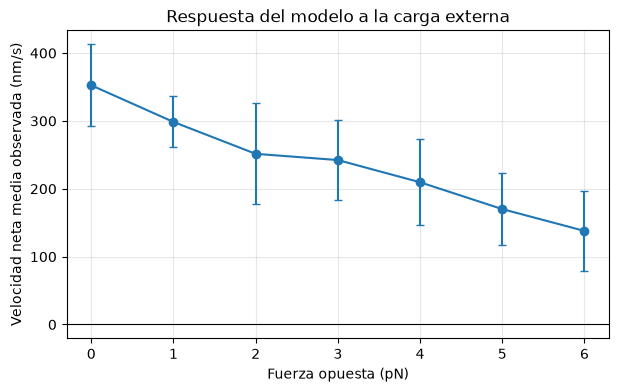

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(forces_pN, mean_velocities, yerr=std_velocities, marker="o", capsize=3)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_xlabel("Fuerza opuesta (pN)")
ax.set_ylabel("Velocidad neta media observada (nm/s)")
ax.set_title("Respuesta del modelo a la carga externa")
ax.grid(alpha=0.3)
plt.show()

## 3. Ver la dependencia de las tasas de avance y retroceso

In [5]:
network = motor.build_network()
for force_pN in (0.0, 2.0, 4.0, 6.0):
    env = replace(base_environment, external_force_N=force_pN * 1e-12)
    rates = {
        transition.event_name: rate
        for transition, rate in network.rates("post_hydrolysis", env)
    }
    print(
        f"{force_pN:4.1f} pN -> "
        f"forward={rates.get('forward_step', 0):.3g} s^-1, "
        f"backward={rates.get('backward_step', 0):.3g} s^-1"
    )

 0.0 pN -> forward=100 s^-1, backward=0.05 s^-1
 2.0 pN -> forward=62.7 s^-1, backward=0.0798 s^-1
 4.0 pN -> forward=39.3 s^-1, backward=0.127 s^-1
 6.0 pN -> forward=24.6 s^-1, backward=0.203 s^-1


**Advertencia:** esta curva no es una curva experimental de kinesina. Se deriva de una ley tipo Bell aplicada a parámetros ilustrativos. La fuerza de parada y la respuesta cuantitativa solo tendrán significado físico después de parametrizar y validar el modelo.